# 05 - Evaluasi di Test Set

**Tujuan:** Mengukur performa model terbaik pada data yang belum pernah dilihat, dibandingkan dengan baseline sederhana.

| | |
|---|---|
| **Input** | `checkpoints/best.pt`, `test.csv`, `train.csv`, `labels.json`, `history.json` |
| **Output** | `reports/metrics/test_metrics.json`, `reports/figures/training_curves.png`, `confusion_food_type.png` |
| **Prasyarat** | Notebook 04 |

> Setiap notebook berdiri sendiri: ia membaca hasil notebook sebelumnya dari Google Drive, jadi sesi Colab boleh diputus/diulang di antara notebook.

In [1]:
# --- Bootstrap (sama di setiap notebook) ---------------------------------------
# 1) Sambungkan Google Drive (tempat semua hasil disimpan permanen)
import os, sys, zipfile
from google.colab import drive
drive.mount('/content/drive')

# 2) Lokasi di Drive: folder ini sekaligus ROOT proyek (zip dan semua hasil ada di sini)
ROOT_ON_DRIVE = "/content/drive/MyDrive/models-train/mmfood-multitask"
ZIP_ON_DRIVE = f"{ROOT_ON_DRIVE}/mmfood-multitask.zip"

# 3) Folder hasil = ROOT di Drive. Harus diset SEBELUM mengimpor config
os.environ["MMFOOD_PROJECT"] = ROOT_ON_DRIVE

# 4) Ekstrak kode + dataset dari zip ke disk lokal Colab (hanya sekali per sesi)
REPO = "/content/mmfood-multitask"
if not os.path.exists(REPO):
    with zipfile.ZipFile(ZIP_ON_DRIVE) as z:
        z.extractall("/content")

# 5) Daftarkan folder src/ agar modul proyek bisa di-import
sys.path.insert(0, f"{REPO}/src")

# 6) Muat path folder (P) dan konfigurasi (CFG) dari src/config.py
from config import get_paths, load_cfg
P = get_paths()       # P.processed, P.checkpoints, P.hf_export, ... (folder dibuat otomatis)
CFG = load_cfg(P)     # nilai bawaan + perubahan dari notebook 00
print("Folder hasil:", P.project)

Mounted at /content/drive
Folder hasil: /content/drive/MyDrive/models-train/mmfood-multitask


In [2]:
# Install library yang dibutuhkan (Colab biasanya sudah punya sebagian; -q = senyap)
!pip install -q transformers accelerate huggingface_hub safetensors scikit-learn pillow tqdm matplotlib

## Langkah 5.1 - Muat model terbaik dan data test

In [3]:
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
from images import restore_images
from dataset import get_transforms, make_loader
from train_utils import build_model, evaluate, to_dev
from data_utils import NUTRITION_KEYS

device = "cuda" if torch.cuda.is_available() else "cpu"
restore_images(P.local_images, f"{P.image_cache}/images.tar")   # pastikan gambar ada di disk lokal

# Muat data dan konfigurasi pra-proses
train_df = pd.read_csv(f"{P.processed}/train.csv")
test_df = pd.read_csv(f"{P.processed}/test.csv")
LABELS = json.load(open(f"{P.artifacts}/labels.json"))
PRE = json.load(open(f"{P.artifacts}/preprocess.json"))

# Bangun model kosong (tanpa unduh backbone), lalu isi dengan bobot terbaik hasil training
model, model_cfg = build_model(CFG, LABELS, device, pretrained_backbone=False)
model.load_state_dict(torch.load(f"{P.checkpoints}/best.pt", map_location=device)["model"])
model.eval()

_, eval_tf = get_transforms(PRE["image_mean"], PRE["image_std"], PRE["img_size"])
test_dl = make_loader(test_df, P.local_images, eval_tf, CFG["batch_size"], False, CFG["num_workers"])
print("Data test:", len(test_df))

config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

Data test: 3600


## Langkah 5.2 - Metrik test dan baseline
**Cara membaca:**
- Akurasi `dish_name` hanya dihitung pada baris yang namanya masuk Top-K.
- MAE nutrisi dalam satuan asli. Baseline = selalu menebak rata-rata data train; model baru bermakna jika MAE-nya jelas lebih kecil dari baseline.

In [4]:
# Evaluasi model pada test set
test_metrics = evaluate(model, test_dl, LABELS, CFG, device)
print(json.dumps({k: round(v, 4) for k, v in test_metrics.items()}, indent=2))

# Baseline: tebak rata-rata nutrisi train untuk semua baris test
base = np.expm1(np.log1p(train_df[NUTRITION_KEYS].values).mean(0))
base_mae = {k: float(np.abs(test_df[k].values - b).mean()) for k, b in zip(NUTRITION_KEYS, base)}
print("\nMAE baseline:", {k: round(v, 1) for k, v in base_mae.items()})
print("MAE model   :", {k: round(test_metrics['mae_' + k], 1) for k in NUTRITION_KEYS})

{
  "loss": 1.8106,
  "acc_food_type": 0.7792,
  "acc_cooking": 0.655,
  "acc_dish": 0.7921,
  "mae_calories_kcal": 95.6775,
  "mae_protein_g": 6.2753,
  "mae_fat_g": 5.2291,
  "mae_carbohydrate_g": 13.2584
}

MAE baseline: {'calories_kcal': 190.1, 'protein_g': 14.1, 'fat_g': 10.6, 'carbohydrate_g': 23.5}
MAE model   : {'calories_kcal': 95.7, 'protein_g': 6.3, 'fat_g': 5.2, 'carbohydrate_g': 13.3}


## Langkah 5.3 - Kurva training

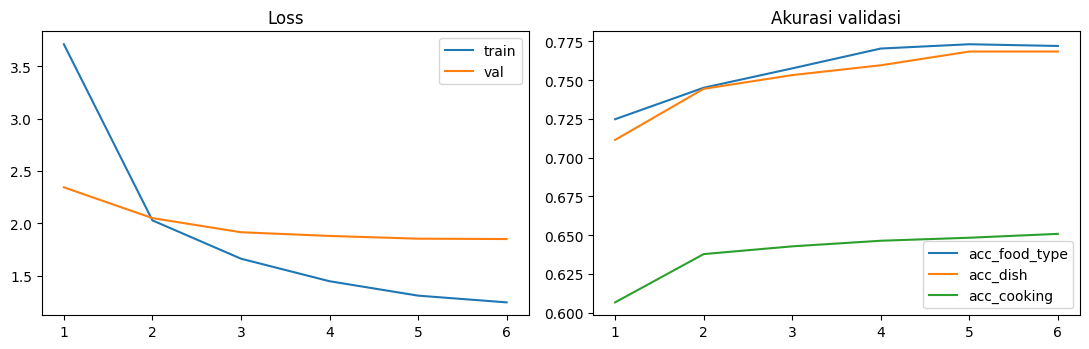

In [5]:
# Plot loss (train vs val) dan akurasi validasi per epoch
h = pd.DataFrame(json.load(open(f"{P.metrics}/history.json")))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.loss, label="val")
ax[0].set_title("Loss"); ax[0].legend()
for c in ["acc_food_type", "acc_dish", "acc_cooking"]:
    ax[1].plot(h.epoch, h[c], label=c)
ax[1].set_title("Akurasi validasi"); ax[1].legend()
plt.tight_layout()
plt.savefig(f"{P.figures}/training_curves.png", dpi=130)
plt.show()

## Langkah 5.4 - Analisis per kelas (`food_type`)
Akurasi total bisa menyesatkan pada kelas tidak seimbang. Laporan per kelas dan confusion matrix menunjukkan kelas mana yang gagal (kemungkinan *Others*).

                           precision    recall  f1-score   support

            Homemade food      0.747     0.840     0.791      1677
                   Others      0.000     0.000     0.000        10
            Packaged food      0.893     0.779     0.832       299
Raw vegetables and fruits      0.896     0.869     0.883       337
          Restaurant food      0.772     0.681     0.723      1277

                 accuracy                          0.779      3600
                macro avg      0.662     0.634     0.646      3600
             weighted avg      0.780     0.779     0.777      3600



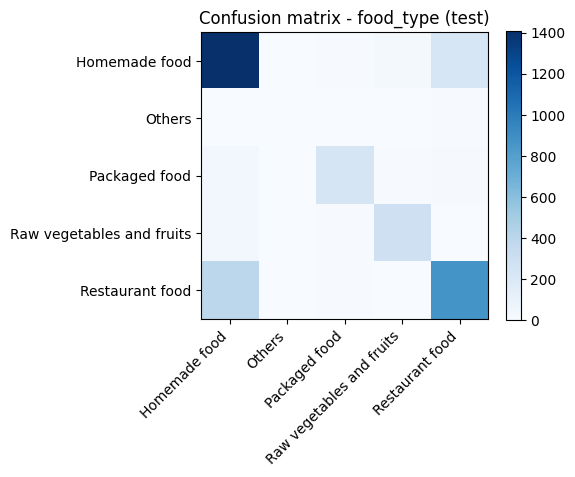

In [6]:
# Kumpulkan prediksi food_type untuk seluruh test set
ys, ps = [], []
with torch.no_grad():
    for b in test_dl:
        b = to_dev(b, device)
        ys += b["food_type"].tolist()
        ps += model(b["pixel_values"])["food_type_logits"].argmax(1).tolist()

# Precision/recall/F1 per kelas
print(classification_report(ys, ps, target_names=LABELS["food_type"], digits=3, zero_division=0))

# Confusion matrix
cm = confusion_matrix(ys, ps, labels=list(range(len(LABELS["food_type"]))))
plt.figure(figsize=(5.8, 4.8))
plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(len(LABELS["food_type"])), LABELS["food_type"], rotation=45, ha="right")
plt.yticks(range(len(LABELS["food_type"])), LABELS["food_type"])
plt.title("Confusion matrix - food_type (test)")
plt.tight_layout()
plt.savefig(f"{P.figures}/confusion_food_type.png", dpi=130)
plt.show()

## Langkah 5.5 - Simpan metrik

In [7]:
# Simpan semua metrik untuk model card (notebook 06) dan laporan
json.dump({"test": test_metrics, "baseline_mae": base_mae,
           "n_train": len(train_df), "n_test": len(test_df)},
          open(f"{P.metrics}/test_metrics.json", "w"), indent=2)
print("Tersimpan:", f"{P.metrics}/test_metrics.json")

Tersimpan: /content/drive/MyDrive/models-train/mmfood-multitask/reports/metrics/test_metrics.json
